Epoch 1/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 0.0242 - val_loss: 0.0107
Epoch 2/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0100 - val_loss: 0.0083
Epoch 3/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0081 - val_loss: 0.0076
Epoch 4/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0074 - val_loss: 0.0072
Epoch 5/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0070 - val_loss: 0.0067
Epoch 6/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0067 - val_loss: 0.0064
Epoch 7/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0063 - val_loss: 0.0062
Epoch 8/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0061 - val_loss: 0.0059
Epoch 9/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0059 - val_loss: 0.0057
Epoch 10/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0057 - val_loss: 0.0056
Epoch 11/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0055 - val_loss: 0.0056
Epoch 12/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step

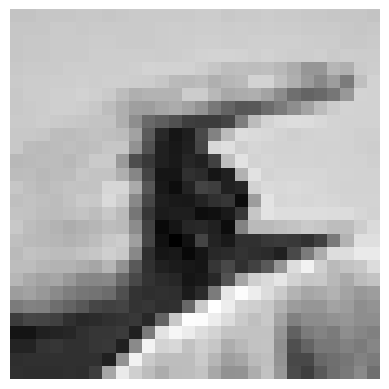


Actual Label: 24
Predicted: Anomaly
Reconstruction Error: 0.014560607341805344
Threshold: 0.008604543010246178


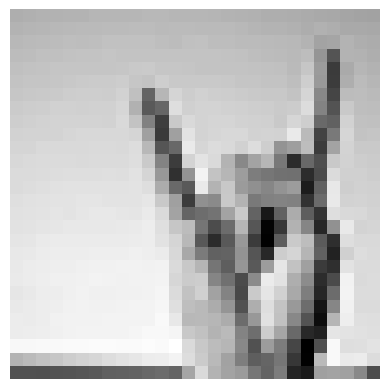

In [5]:
import pandas as pd
import numpy as np
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# 1. Load datasets
train = pd.read_csv("Datasets/AutoEncoder/Sign Language MNIST/sign_mnist_train.csv")
test = pd.read_csv("Datasets/AutoEncoder/Sign Language MNIST/sign_mnist_test.csv")

X_train = train.drop("label", axis=1).values / 255.0
y_train = train["label"].values

X_test = test.drop("label", axis=1).values / 255.0
y_test = test["label"].values

# 2. Keep only normal classes for training
X_train = X_train[y_train != 24]

# 3. Build Autoencoder
inp = Input(shape=(784,))
x = Dense(128, activation="relu")(inp)
x = Dense(64, activation="relu")(x)
x = Dense(128, activation="relu")(x)
out = Dense(784, activation="sigmoid")(x)

model = Model(inp, out)
model.compile(optimizer="adam", loss="mse")

# 4. Train the model
model.fit(X_train, X_train, epochs=20, batch_size=32,
          validation_split=0.1)

# 5. Calculate reconstruction error
reconstructed = model.predict(X_test)
error = np.mean((X_test - reconstructed) ** 2, axis=1)

threshold = np.percentile(
    np.mean((X_train - model.predict(X_train)) ** 2, axis=1), 95
)

# 6. Detect anomalies
predictions = (error > threshold).astype(int)
actual = (y_test == 24).astype(int)

print("Threshold:", threshold)
print("Actual anomalies:", actual.sum())
print("Detected anomalies:", predictions.sum())
print("Accuracy:", np.mean(predictions == actual))

import matplotlib.pyplot as plt

for idx in [np.where(y_test != 24)[0][0], np.where(y_test == 24)[0][0]]:

    plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    plt.axis("off")
    plt.show()

    print("Actual Label:", y_test[idx])
    print("Prediction:", "Anomaly" if predictions[idx] == 1 else "Normal")
    print("Reconstruction Error:", error[idx])
    print("Threshold:", threshold)
    print("-------------------")

Epoch 1/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 0.0226 - val_loss: 0.0103
Epoch 2/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0095 - val_loss: 0.0083
Epoch 3/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0079 - val_loss: 0.0073
Epoch 4/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0071 - val_loss: 0.0068
Epoch 5/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0067 - val_loss: 0.0066
Epoch 6/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0064 - val_loss: 0.0063
Epoch 7/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0061 - val_loss: 0.0063
Epoch 8/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0059 - val_loss: 0.0058
Epoch 9/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0057 - val_loss: 0.0057
Epoch 10/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0056 - val_loss: 0.0055
Epoch 11/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0055 - val_loss: 0.0054
Epoch 12/20
741/741 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step

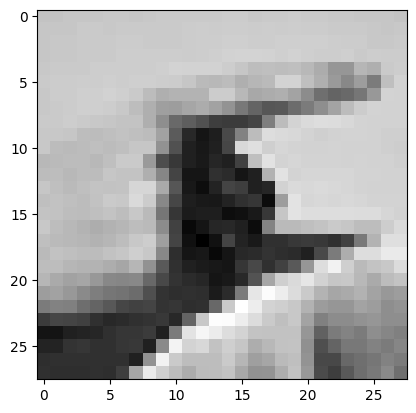

Actual Label:  6
Predicted Label:  Normal
Reconstruction Error:  0.003991616483141385
Threshold:  0.008467441487248732


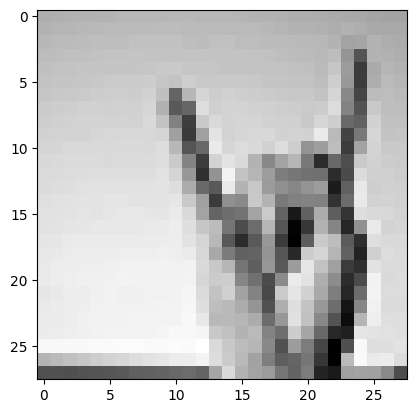

Actual Label:  24
Predicted Label:  Anomaly
Reconstruction Error:  0.013837103655682501
Threshold:  0.008467441487248732


In [8]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

train_data = pd.read_csv("Datasets/AutoEncoder/Sign Language MNIST/sign_mnist_train.csv")
test_data = pd.read_csv("Datasets/AutoEncoder/Sign Language MNIST/sign_mnist_test.csv")

x_train = train_data.drop("label", axis=1).values / 255.0
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values / 255.0
y_test = test_data["label"].values

x_train = x_train[y_train != 24]

inp = Input(shape=(784,))
en = Dense(128, activation='relu')(inp)
en = Dense(64, activation='relu')(en)
en = Dense(128, activation='relu')(en)
out = Dense(784, activation='sigmoid')(en)

model = Model(inp, out)

model.compile(optimizer='adam', loss='mse')

model.fit(x_train, x_train, epochs=20, batch_size=32, validation_split=0.1)

recon = model.predict(x_test, verbose=0)
error = np.mean((x_test - recon) ** 2, axis=1)

threshold = np.percentile(np.mean((x_train - model.predict(x_train, verbose=0)) ** 2, axis=1), 95)

preds = (error > threshold).astype("int")
actual = (y_test == 24).astype("int")

print("Threshold: ", threshold)
print("Actual Anomalies (Label - Y): ", actual.sum())
print("Predictions: ", preds.sum())
print("Accuracy: ", np.mean(preds == actual))

nor_ind = np.where(y_test != 24)[0][0]
an_ind = np.where(y_test == 24)[0][0]

for ind in [nor_ind, an_ind]:
    plt.imshow(x_test[ind].reshape(28, 28), cmap='gray')
    plt.show()

    print("Actual Label: ", y_test[ind])
    print("Predicted Label: ", "Anomaly" if preds[ind] == 1 else "Normal")
    print("Reconstruction Error: ", error[ind])
    print("Threshold: ", threshold)